In [48]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt


In [49]:
data_directory = "data"

community = gpd.read_file(f"{data_directory}/Community_Floodplain/Community_Floodplain.shp")
fema = gpd.read_file(f"{data_directory}/FEMA_Floodplain/FEMA_Floodplain.shp")
drainage = gpd.read_file(f"{data_directory}/drainage.geojson")
fire = gpd.read_file(f"{data_directory}/Current_CFD_Fire_Stations.geojson")
streets = gpd.read_file(f"{data_directory}/streets.geojson")
storm_data = pd.read_csv(f"{data_directory}/storm_data.csv")
mecklenburg_boundary = gpd.read_file(f"{data_directory}/Mecklenburg/Sphere_of_Influence.shp")


In [50]:
target_crs = "EPSG:2264"

community = community.to_crs(target_crs)
fema = fema.to_crs(target_crs)
drainage = drainage.to_crs(target_crs)
fire = fire.to_crs(target_crs)
streets = streets.to_crs(target_crs)
mecklenburg_boundary = mecklenburg_boundary.to_crs(target_crs)


Community Floodplain

Source: Charlotte-Mecklenburg Storm Water Services  
https://www.charlottenc.gov/Services/Stormwater/Data-Apps


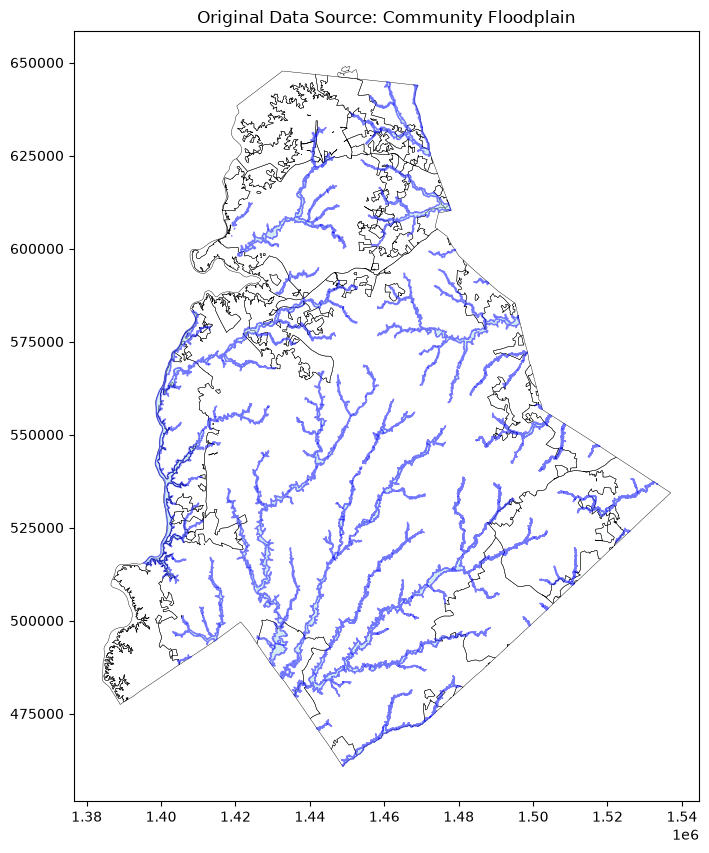

In [51]:
fig, ax = plt.subplots(figsize=(10, 10))
mecklenburg_boundary.plot(ax=ax, color="none", edgecolor="black", linewidth=0.3)
community.plot(ax=ax, color="lightblue", alpha=0.5, edgecolor="blue")

ax.set_title("Original Data Source: Community Floodplain")
plt.show()


FEMA Floodplain

Source: Charlotte-Mecklenburg Storm Water Services / FEMA  
https://www.charlottenc.gov/Services/Stormwater/Data-Apps


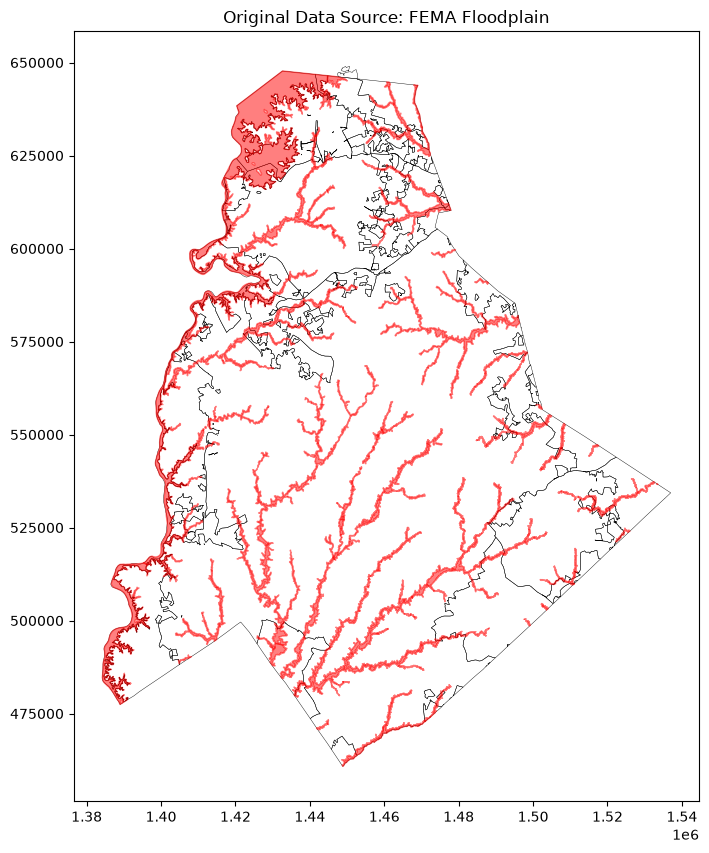

In [52]:
fig, ax = plt.subplots(figsize=(10, 10))

mecklenburg_boundary.plot(ax=ax, color="none", edgecolor="black", linewidth=0.3)
fema.plot(ax=ax, color="red", alpha=0.5, edgecolor="red")

ax.set_title("Original Data Source: FEMA Floodplain")
plt.show()

Drainage Features

Source: City of Charlotte GIS Storm Drainage data  
https://gis.charlottenc.gov/arcgis/rest/services/STM/StormDrainage/MapServer


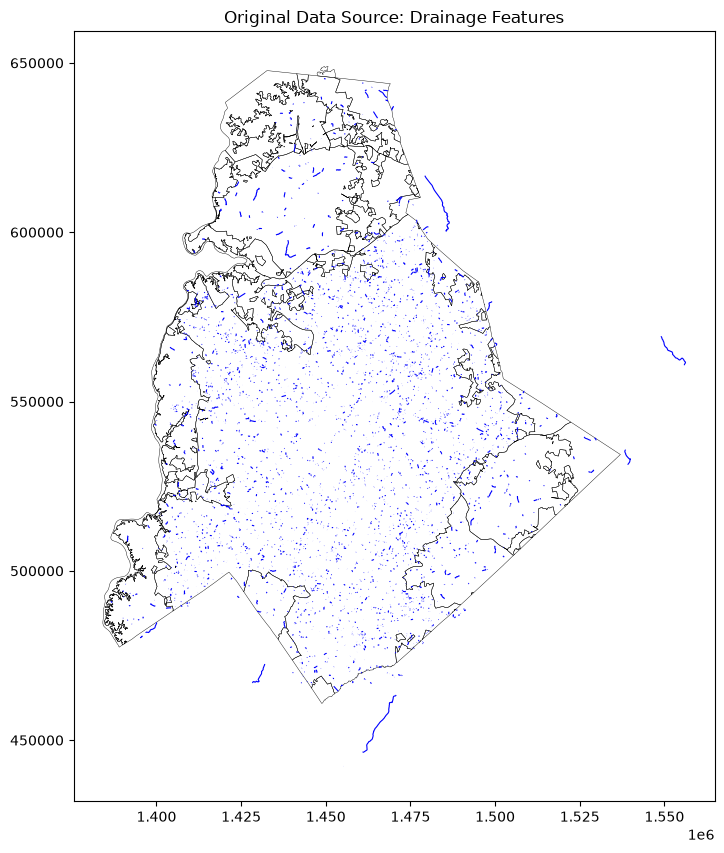

In [53]:
fig, ax = plt.subplots(figsize=(10, 10))

mecklenburg_boundary.plot(ax=ax, color="none", edgecolor="black", linewidth=0.3)
drainage.plot(ax=ax, color="blue", linewidth=0.8)

ax.set_title("Original Data Source: Drainage Features")
plt.show()


Fire Stations

Source: City of Charlotte GIS  
https://arcg.is/1TT1a3


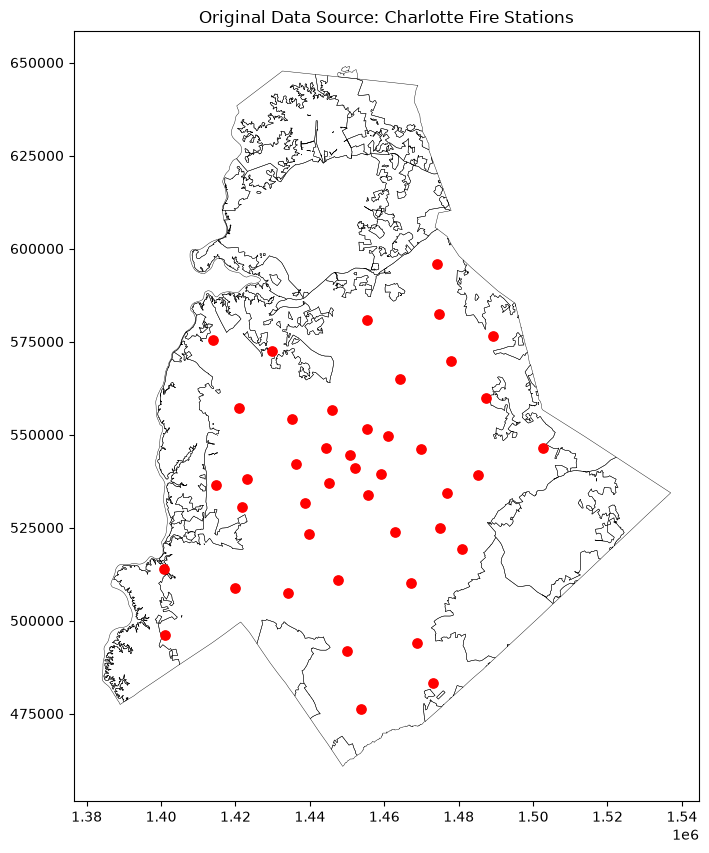

In [54]:
fig, ax = plt.subplots(figsize=(10, 10))

mecklenburg_boundary.plot(ax=ax, color="none", edgecolor="black", linewidth=0.3)
fire.plot(ax=ax, color="red", markersize=45)

ax.set_title("Original Data Source: Charlotte Fire Stations")
plt.show()


Streets

Source: City of Charlotte / Mecklenburg County GIS  
https://gis.charlottenc.gov/arcgis/rest/services/CountyData/Streets/MapServer


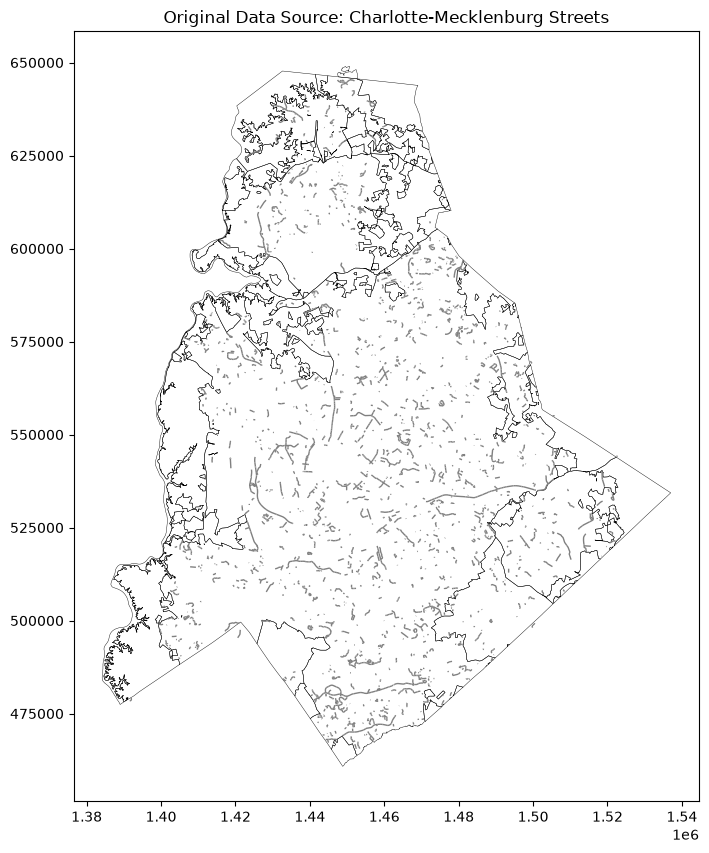

In [55]:
fig, ax = plt.subplots(figsize=(10, 10))

mecklenburg_boundary.plot(ax=ax, color="none", edgecolor="black", linewidth=0.3)
streets.plot(ax=ax, color="gray", linewidth=1)

ax.set_title("Original Data Source: Charlotte-Mecklenburg Streets")
plt.show()


NOAA Storm Events Table

Source: NOAA National Centers for Environmental Information, Storm Events Database  
https://www.ncei.noaa.gov/access/storm-events-database/

(on-spatial table used for the tabular join)


In [56]:
storm_data.head()


,EVENT_ID,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,BEGIN_TIME,EVENT_TYPE,MAGNITUDE,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,...,END_LOCATION,END_DATE,END_TIME,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EVENT_NARRATIVE,EPISODE_NARRATIVE,STATE
0,645525,MECKLENBURG CO.,RAMA,06/14/2016,1913,Thunderstorm Wind,50.00,NaN,0,0,...,IDLEWILD,06/14/2016,1913,35.200,-80.770,35.21,-80.76,FD reported a tree blown down on Kistler Ave. ...,Scattered thunderstorms moved into southern No...,NORTH CAROLINA
1,645526,MECKLENBURG CO.,OAKHURST,06/14/2016,1911,Hail,0.75,NaN,0,0,...,OAKHURST,06/14/2016,1911,35.200,-80.790,35.20,-80.79,Public reported (via Social Media) 3/4 inch ha...,Scattered thunderstorms moved into southern No...,NORTH CAROLINA
2,646510,MECKLENBURG CO.,DAVIDSON,06/29/2016,1544,Thunderstorm Wind,50.00,NaN,0,0,...,DAVIDSON,06/29/2016,1544,35.500,-80.850,35.50,-80.85,County comms reported multiple trees blown dow...,Scattered thunderstorms developed along the Bl...,NORTH CAROLINA
3,649044,MECKLENBURG CO.,GRIFFITH,07/05/2016,1527,Thunderstorm Wind,50.00,NaN,0,0,...,STONEHAVEN,07/05/2016,1545,35.191,-80.851,35.16,-80.73,County comms reported multiple trees blown dow...,A line of thunderstorms moved into western Nor...,NORTH CAROLINA
4,649530,MECKLENBURG CO.,CHADWICK,07/08/2016,1931,Thunderstorm Wind,50.00,NaN,0,0,...,OAKHURST,07/08/2016,1940,35.281,-80.913,35.23,-80.79,"County comms, HAM Radio operators, and the pub...","For the fourth day in a row, a line of organiz...",NORTH CAROLINA


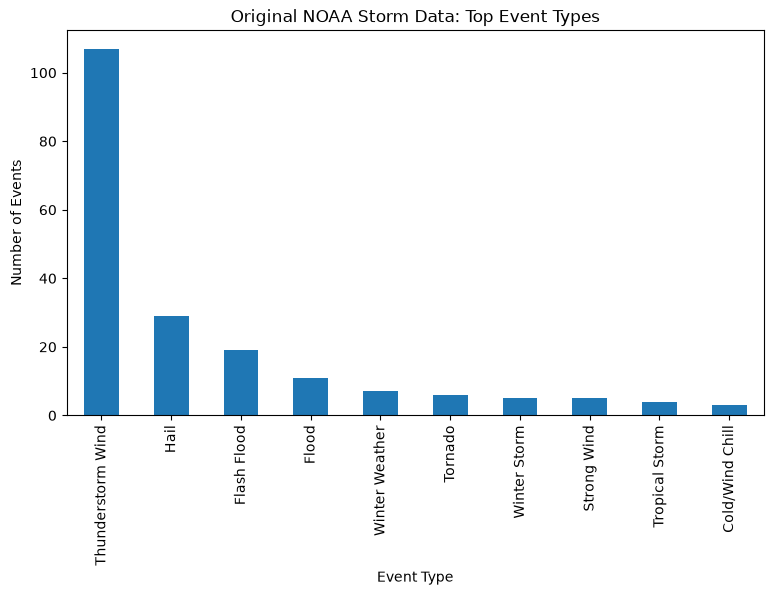

In [57]:
storm_type_counts = storm_data["EVENT_TYPE"].value_counts().head(10)

ax = storm_type_counts.plot(kind="bar",figsize=(9, 5))

ax.set_title("Original NOAA Storm Data: Top Event Types")
ax.set_xlabel("Event Type")
ax.set_ylabel("Number of Events")

plt.show()


Combined Map

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))

mecklenburg_boundary.plot(ax=ax, color="none", edgecolor="black", linewidth=0.3)
community.plot(ax=ax, color="lightblue", alpha=0.25, edgecolor="blue") 
fema.plot(ax=ax, color="red", alpha=0.25, edgecolor="red")
streets.plot(ax=ax, color="gray", alpha=0.45, linewidth=0.5)
drainage.plot(ax=ax, color="blue", linewidth=0.7)
fire.plot(ax=ax, color="red", markersize=25)

ax.set_title("Original Project Data Sources Together")
plt.show()


Questions

1. Which street segments intersect the community floodplain?
2. Which fire stations are close to drainage features?
3. Which flood-exposed streets are near Fire Station 1?
4. What storm-event history from the NOAA table can be joined to the FEMA floodplain layer?


## 10. Analysis Methods

- Spatial join: used to find streets that intersect the community floodplain
- Buffer: used to create 500-foot areas around drainage features
- Distance: used to measure how close flood-exposed streets are to Fire Station 1
- Attribute join: used to join the NOAA storm-event summary table to the FEMA floodplain polygons


## 11. Results to Mention in Presentation

Use the final project notebook results here:
- total number of flood-exposed street segments
- number of fire stations near drainage
- number of flood-exposed streets near Fire Station 1
- most common NOAA storm event types
